# COMP1013 — Individual Project 2.2: Multimodal Science Question Answering

**Dataset:** `lmms-lab/ScienceQA-IMG` (Hugging Face)  
**Methods:** BERT text-only control; BERT+ViT early fusion; BERT-query/ViT-patch intermediate cross-attention.  
**Evaluation:** accuracy, cross-entropy, Brier score, expected calibration error (ECE), training curves, runtime/memory, grouped paired bootstrap differences, subgroups, image-shuffling.

## 0 — Packages and reproducible configuration

For reproducibility, the notebook exports the exact installed versions after running. The full pipeline uses `datasets`, `transformers`, `torch`, NumPy, Pandas, scikit-learn, Pillow and Matplotlib.

In [ ]:
%pip -q install "datasets>=3.0,<5" "transformers>=4.44,<5" "accelerate>=0.33" "scikit-learn>=1.3" "pillow>=10" "pandas>=2" "matplotlib>=3.7" "tqdm>=4.66" "safetensors>=0.4"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
from pathlib import Path
import os, io, gc, re, json, time, random, math, hashlib, copy, platform, sys
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from PIL import Image, ImageOps
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel, AutoImageProcessor

DATASET_ID = "lmms-lab/ScienceQA-IMG"
TEXT_ENCODER = "bert-base-uncased"
IMAGE_ENCODER = "google/vit-base-patch16-224-in21k"
SEED = 42
QUICK_RUN = False            # FULL cleaned dataset and three seeds: [13, 42, 73]
QUICK_LIMITS = {"train": 1600, "validation": 450, "test": 450}
SEEDS = [42] if QUICK_RUN else [13, 42, 73]
MAX_CHOICES = 5
MAX_TEXT_TOKENS = 128
PATCH_POOL = 2              # ViT 14x14 patch grid -> 7x7 = 49 tokens (memory-efficient)
BERT_BATCH = 24
VIT_BATCH = 8
TRAIN_BATCH = 32
MAX_EPOCHS = 10
PATIENCE = 3
LR = 3e-4
WEIGHT_DECAY = 1e-2
DROPOUT = 0.25
HIDDEN = 256
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = Path('/content/scienceqa_project22' if Path('/content').exists() else 'scienceqa_project22').resolve()
CACHE = ROOT / 'cache'
RESULTS = ROOT / 'results'
CHECKPOINTS = ROOT / 'checkpoints'
for d in (CACHE, RESULTS, CHECKPOINTS): d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print('PyTorch',torch.__version__,'Device', DEVICE, 'QUICK_RUN', QUICK_RUN, 'ROOT', ROOT)
if DEVICE.type != 'cuda': print('WARNING: No GPU. BERT/ViT extraction will be slow; use a Colab T4 if possible.')

PyTorch 2.14.1+cu130 Device cuda QUICK_RUN False ROOT /content/scienceqa_project22


## 1 — Load the exact ScienceQA-IMG dataset and check structure

The source is a formatted *image-containing* subset of ScienceQA, not the full ScienceQA corpus.

In [ ]:
raw = load_dataset(DATASET_ID)
expected = {'train': 6218, 'validation': 2097, 'test': 2017}
required = {'image','question','choices','answer','hint','grade','subject','lecture','solution'}
assert all(s in raw for s in expected), f"Unexpected splits: {list(raw)}"
for s, n in expected.items():
    assert len(raw[s]) == n, f"Unexpected {s} length {len(raw[s])} (expected {n})"
    assert required.issubset(set(raw[s].column_names)), (s, raw[s].column_names)
print(raw)
print('Columns:',raw['train'].column_names)
print('Question example:',raw['train'][0]['question'])
print('Number of options:',len(raw['train'][0]['choices']))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/400M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/133M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/130M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6218 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2097 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2017 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 6218
    })
    validation: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 2097
    })
    test: Dataset({
        features: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution'],
        num_rows: 2017
    })
})
Columns: ['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution']
Question example: Which of these states is farthest north?
Number of options: 4


## 2 — Complete data-quality audit and leakage screening

Audit *all original rows before sampling*, so a quick run does not accidentally hide cross-split overlap. Validate readable images, nonblank questions, 2–5 options and answer indices. Exact image IDs use SHA-256 of canonical RGB pixel values (including dimensions); identical question+option fingerprints use normalised whitespace/case. These are **exact-content** checks, not near-duplicate detection.

When the same image/text appears in multiple supplied splits, keep the **evaluation split first** (test, then validation) and remove conflicting lower-priority rows. Multiple distinct questions using the same image **within one split** remain allowed. Record all removals. This maintains a clean held-out evaluation instead of promoting potentially leaked test examples into training.

In [ ]:
def norm_text(x):
    return re.sub(r'\s+', ' ', str(x if x is not None else '').strip().casefold())

def question_digest(q, choices):
    content = [norm_text(q), [norm_text(x) for x in choices]]
    return hashlib.sha256(json.dumps(content, ensure_ascii=False).encode('utf-8')).hexdigest()

def pixel_digest(image):
    image = image.convert('RGB')
    h = hashlib.sha256()
    h.update(f'{image.size[0]}x{image.size[1]}:'.encode('utf-8'))
    h.update(image.tobytes())
    return h.hexdigest()

AUDIT_FILE = CACHE / 'audit_all_records.json'
if AUDIT_FILE.exists():
    records = json.loads(AUDIT_FILE.read_text())
else:
    records = []
    for split in ('train','validation','test'):
        for index in tqdm(range(len(raw[split])), desc=f'Audit {split}'):
            try:
                r = raw[split][index]
                choices = list(r['choices'] or [])
                valid = bool(norm_text(r['question'])) and 2 <= len(choices) <= MAX_CHOICES
                valid = valid and all(bool(norm_text(c)) for c in choices)
                valid = valid and 0 <= int(r['answer']) < len(choices)
                if not valid: raise ValueError('Invalid question/choices/answer')
                pix = pixel_digest(r['image'])
                td = question_digest(r['question'], choices)
                records.append({'split':split,'index':index,'image_hash':pix,
                    'text_hash':td,'answer':int(r['answer']),'n_choices':len(choices),
                    'subject':str(r.get('subject') or 'Unknown'),
                    'grade':str(r.get('grade') or 'Unknown'),
                    'hint_blank':not bool(norm_text(r.get('hint'))),
                    'valid':True,'invalid_reason':None})
            except Exception as ex:
                records.append({'split':split,'index':index,'valid':False,
                                'invalid_reason':type(ex).__name__ + ': ' + str(ex)[:150]})
    AUDIT_FILE.write_text(json.dumps(records, indent=2))

# Keep test, then validation, then training in any cross-split collision.
prior_images, prior_text = set(),set()
for split in ('test','validation','train'):
    current_image, current_text = set(),set()
    for row in (x for x in records if x['split']==split):
        if not row['valid']:
            row['decision'] = 'invalid'
            continue
        if row['image_hash'] in prior_images:
            row['decision'] = 'cross_split_image'
        elif row['text_hash'] in prior_text:
            row['decision'] = 'cross_split_text'
        else:
            row['decision'] = 'keep'
            current_image.add(row['image_hash'])
            current_text.add(row['text_hash'])
    prior_images |= current_image
    prior_text |= current_text

full_clean = {s: [r for r in records if r['split']==s and r['decision']=='keep']
              for s in ('train','validation','test')}
audit_df = pd.DataFrame(records)
print(pd.crosstab(audit_df.split, audit_df.decision))
print('Clean sizes:',{s:len(v) for s,v in full_clean.items()})
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    A={r['image_hash'] for r in full_clean[a]}; B={r['image_hash'] for r in full_clean[b]}
    assert not A.intersection(B), f'Image overlap: {a}/{b}'
    A={r['text_hash'] for r in full_clean[a]}; B={r['text_hash'] for r in full_clean[b]}
    assert not A.intersection(B), f'Text overlap: {a}/{b}'
(audit_df[['split','index','valid','decision','invalid_reason']]
    .to_csv(RESULTS/'audit_decisions.csv', index=False))

Audit train:   0%|          | 0/6218 [00:00<?, ?it/s]

Audit validation:   0%|          | 0/2097 [00:00<?, ?it/s]

Audit test:   0%|          | 0/2017 [00:00<?, ?it/s]

decision    cross_split_image  cross_split_text  keep
split                                                
test                        0                 0  2017
train                    1467              1221  3530
validation                378               376  1343
Clean sizes: {'train': 3530, 'validation': 1343, 'test': 2017}


## 3 — Select records for a pilot/full run

Sampling is **after** split hygiene. Full mode retains every valid, non-overlapping record. Quick mode uses a fixed-seed random sample solely for pipeline validation and does not stand in for full-dataset performance. The three configurations always use exactly the same examples.

In [ ]:
rng = np.random.default_rng(SEED)
selected = {}
for split, rows in full_clean.items():
    limit = min(len(rows), QUICK_LIMITS[split]) if QUICK_RUN else len(rows)
    chosen = sorted(rng.choice(len(rows), size=limit, replace=False).tolist())
    selected[split] = [rows[j] for j in chosen]
print('Selected:', {s:len(v) for s,v in selected.items()})
print('Mean chance-level accuracy on sampled test set:',
      float(np.mean([1/r['n_choices'] for r in selected['test']])))

manifest = {
    'dataset': DATASET_ID, 'text_encoder':TEXT_ENCODER, 'image_encoder':IMAGE_ENCODER,
    'quick_run':QUICK_RUN, 'max_text_tokens':MAX_TEXT_TOKENS, 'patch_pool':PATCH_POOL,
    'original_sizes':expected,
    'clean_sizes':{s:len(v) for s,v in full_clean.items()},
    'sampled_sizes':{s:len(v) for s,v in selected.items()},
    'seeds':SEEDS,
    'excluded_input_columns':['lecture','solution'],
    'overlap_policy':'test > validation > train; exact canonical RGB or normalised question+choices',
    'audit_decisions':audit_df.groupby(['split','decision']).size().to_dict().__str__(),
    'hyperparameters':{'batch':TRAIN_BATCH,'lr':LR,'epochs':MAX_EPOCHS,'patience':PATIENCE,
                       'weight_decay':WEIGHT_DECAY,'hidden':HIDDEN,'dropout':DROPOUT},
}
(RESULTS/'experiment_manifest.json').write_text(json.dumps(manifest, indent=2))

Selected: {'train': 3530, 'validation': 1343, 'test': 2017}
Mean chance-level accuracy on sampled test set: 0.35494959510824653


1094

## 4 — Encode each modality using frozen pretrained encoders

Topic 3: modality-specific feature extraction. **BERT** encodes each question–candidate option pair; optional hints are included when available, not imputed or treated as target labels. **ViT** encodes images letterboxed to 224×224 (aspect ratio preserved) as patch sequences, with padding masks. To make Colab T4 memory manageable, ViT's 14×14 patch grid is spatially pooled 2×2 to 7×7 while preserving 49 local image representations for the attention model.

The models are frozen and used only under `torch.inference_mode()`; training later updates only the fusion/classification heads. We do not use `lecture` or `solution` in prompts or features. Cache results by dataset/configuration fingerprint to avoid repeated expensive feature extraction.

In [ ]:
selected_signature = hashlib.sha256(json.dumps(
    {s:[r['index'] for r in selected[s]] for s in selected}, sort_keys=True).encode()).hexdigest()[:12]
feature_file = CACHE / f'features_{"quick" if QUICK_RUN else "full"}_{selected_signature}_len{MAX_TEXT_TOKENS}_pool{PATCH_POOL}.pt'

def image_embeddings_for_split(split, rows, processor, vit):
    # Each repeated image inside the same split is encoded once.
    # Aspect-ratio-preserving letterboxing is paired with valid-patch masks.
    first = {}
    for r in rows:
        first.setdefault(r['image_hash'], r['index'])
    keys = list(first.keys()); embeddings = {}
    for start in tqdm(range(0,len(keys),VIT_BATCH),desc=f'ViT {split}'):
        keys_b = keys[start:start+VIT_BATCH]
        ims=[]; valid_masks=[]
        for h in keys_b:
            orig=raw[split][first[h]]['image'].convert('RGB')
            w,height=orig.size; side_px=224
            scale=min(side_px/w,side_px/height)
            target_w=min(side_px,round(w*scale));target_h=min(side_px,round(height*scale))
            left=(side_px-target_w)//2; top=(side_px-target_h)//2
            ims.append(ImageOps.pad(orig,(side_px,side_px),method=Image.Resampling.BICUBIC,
                                    color=(255,255,255),centering=(0.5,0.5)))
            pooled_side=(224//16)//PATCH_POOL
            # Patch-center validity after pooling. True means visual content, not padding.
            valid=np.array([left <= (x+.5)*side_px/pooled_side < left+target_w and
                top <= (y+.5)*side_px/pooled_side < top+target_h
                for y in range(pooled_side) for x in range(pooled_side)],dtype=bool)
            if not valid.any(): valid[:]=True
            valid_masks.append(valid)
        inp = processor(images=ims, return_tensors='pt').to(DEVICE)
        with torch.inference_mode():
            with torch.autocast(device_type='cuda', enabled=(DEVICE.type=='cuda')):
                z = vit(**inp).last_hidden_state[:,1:,:]  # exclude CLS
                n = z.size(1); side = math.isqrt(n)
                if side*side != n: raise RuntimeError(f'Unexpected ViT patch count: {n}')
                z = z.transpose(1,2).reshape(z.size(0),z.size(-1),side,side)
                z = F.avg_pool2d(z, kernel_size=PATCH_POOL, stride=PATCH_POOL)
                z = z.flatten(2).transpose(1,2)
        for key, vec, valid in zip(keys_b,z.cpu().numpy().astype(np.float16),valid_masks):
            embeddings[key] = (vec,valid)
    return (torch.from_numpy(np.stack([embeddings[r['image_hash']][0] for r in rows])),
            torch.from_numpy(np.stack([embeddings[r['image_hash']][1] for r in rows])))

def candidate_prompt(row, choice):
    question = str(row['question'])
    hint = str(row.get('hint') or '').strip()
    return f"Question: {question} " + (f"Context: {hint} " if hint else '') + f"Candidate answer: {choice}"

def text_embeddings_for_split(split, rows, tokenizer, bert):
    prompts=[]; slots=[]
    for i,r in enumerate(rows):
        ex=raw[split][r['index']]
        for c,ch in enumerate(ex['choices']):
            prompts.append(candidate_prompt(ex,ch))
            slots.append((i,c))
    n=len(rows)
    tensor=np.zeros((n,MAX_CHOICES,bert.config.hidden_size), dtype=np.float16)
    masks=np.zeros((n,MAX_CHOICES),dtype=bool)
    # Token lengths are measured on a reproducible sample; not full prompt scan.
    measured = [len(tokenizer.encode(p, add_special_tokens=True)) for p in prompts[:min(1000,len(prompts))]]
    truncated = sum(x>MAX_TEXT_TOKENS for x in measured)
    print(f'{split} sampled token truncation: {truncated}/{len(measured)} prompts')
    for start in tqdm(range(0,len(prompts),BERT_BATCH),desc=f'BERT {split}'):
        ss=prompts[start:start+BERT_BATCH]
        inp=tokenizer(ss,padding=True,truncation=True,max_length=MAX_TEXT_TOKENS,
                      return_tensors='pt').to(DEVICE)
        with torch.inference_mode():
            with torch.autocast(device_type='cuda', enabled=(DEVICE.type=='cuda')):
                hidden=bert(**inp).last_hidden_state[:,0,:]
        vectors=hidden.cpu().numpy().astype(np.float16)
        for (i,c),vec in zip(slots[start:start+BERT_BATCH], vectors):
            tensor[i,c]=vec; masks[i,c]=True
    return torch.from_numpy(tensor),torch.from_numpy(masks), {'truncated':truncated,'measured':len(measured)}

if feature_file.exists():
    print('Loading cached features:',feature_file)
    features = torch.load(feature_file,map_location='cpu',weights_only=True)
else:
    print('Extracting frozen ViT image features...')
    image_processor=AutoImageProcessor.from_pretrained(IMAGE_ENCODER)
    vit=AutoModel.from_pretrained(IMAGE_ENCODER).eval().to(DEVICE)
    image_data = {s:image_embeddings_for_split(s,selected[s],image_processor,vit)
                  for s in ('train','validation','test')}
    del vit,image_processor; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    print('Extracting frozen BERT text features...')
    tokenizer=AutoTokenizer.from_pretrained(TEXT_ENCODER)
    bert=AutoModel.from_pretrained(TEXT_ENCODER).eval().to(DEVICE)
    features={}
    truncation_report={}
    for s in ('train','validation','test'):
        text_data,mask,stats=text_embeddings_for_split(s,selected[s],tokenizer,bert)
        truncation_report[s]=stats
        features[s]={
            'text':text_data,'patches':image_data[s][0],'patch_mask':image_data[s][1], 'mask':mask,
            'labels':torch.tensor([r['answer'] for r in selected[s]],dtype=torch.long)
        }
    del bert,tokenizer,image_data; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    torch.save(features,feature_file)
    (RESULTS/'token_truncation_sample.json').write_text(json.dumps(truncation_report,indent=2))

for s in features:
    a=features[s]
    assert a['text'].shape[:2] == (len(selected[s]),MAX_CHOICES)
    assert a['patches'].shape[0] == len(selected[s])
    assert a['patch_mask'].shape == a['patches'].shape[:2]
    assert a['patches'].shape[-1] == a['text'].shape[-1]
    assert torch.all(a['mask'].sum(dim=1)>=2)
    print(s,{k:tuple(v.shape) for k,v in a.items()})

Extracting frozen ViT image features...


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

ViT train:   0%|          | 0/400 [00:00<?, ?it/s]

... (11 outputs left out)

BERT validation:   0%|          | 0/186 [00:00<?, ?it/s]

test sampled token truncation: 90/1000 prompts


BERT test:   0%|          | 0/260 [00:00<?, ?it/s]

train {'text': (3530, 5, 768), 'patches': (3530, 49, 768), 'patch_mask': (3530, 49), 'mask': (3530, 5), 'labels': (3530,)}
validation {'text': (1343, 5, 768), 'patches': (1343, 49, 768), 'patch_mask': (1343, 49), 'mask': (1343, 5), 'labels': (1343,)}
test {'text': (2017, 5, 768), 'patches': (2017, 49, 768), 'patch_mask': (2017, 49), 'mask': (2017, 5), 'labels': (2017,)}


## 5 — Models: text-only, early fusion, and cross-attention intermediate fusion

- **Text baseline:** one scorer per question-option text embedding, image ignored.
- **Early fusion:** concatenate projected BERT option embedding with projected *pooled* ViT image embedding and score.
- **Intermediate fusion:** each BERT option embedding is a query to a `MultiheadAttention` block over ViT **patch keys/values**, followed by a learned scorer. Spatial patch masks prevent cross-attention to letterboxed padding.

The `mask` prevents invalid padded options (option counts vary from 2 to 5) receiving any probability. All models share the same frozen input features, train/validation/test records and training protocol.

In [ ]:
class TextOnly(nn.Module):
    def __init__(self, dim=768, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.score = nn.Sequential(nn.LayerNorm(dim),nn.Linear(dim,hidden),
                                   nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self, text, patches, mask, patch_mask=None):
        logits=self.score(text).squeeze(-1)
        return logits.masked_fill(~mask,-1e4)

class EarlyFusion(nn.Module):
    def __init__(self, dim=768, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.tproj=nn.Sequential(nn.LayerNorm(dim),nn.Linear(dim,hidden),nn.ReLU())
        self.vproj=nn.Sequential(nn.LayerNorm(dim),nn.Linear(dim,hidden),nn.ReLU())
        self.score=nn.Sequential(nn.Linear(2*hidden,hidden),nn.ReLU(),
                                 nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,text,patches,mask,patch_mask=None):
        t=self.tproj(text)
        if patch_mask is None: patch_mask=torch.ones(patches.shape[:2],dtype=torch.bool,device=patches.device)
        weighted=(patches*patch_mask.unsqueeze(-1)).sum(dim=1)/patch_mask.sum(dim=1).clamp(min=1).unsqueeze(-1)
        v=self.vproj(weighted).unsqueeze(1).expand(-1,text.size(1),-1)
        logits=self.score(torch.cat([t,v],dim=-1)).squeeze(-1)
        return logits.masked_fill(~mask,-1e4)

class IntermediateFusion(nn.Module):
    def __init__(self, dim=768, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.tproj=nn.Sequential(nn.LayerNorm(dim),nn.Linear(dim,hidden))
        self.vproj=nn.Sequential(nn.LayerNorm(dim),nn.Linear(dim,hidden))
        self.cross_attention=nn.MultiheadAttention(hidden,4,dropout=dropout,batch_first=True)
        self.norm=nn.LayerNorm(hidden)
        self.score=nn.Sequential(nn.Linear(2*hidden,hidden),nn.ReLU(),
                                 nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,text,patches,mask,patch_mask=None):
        tq=self.tproj(text); vk=self.vproj(patches)
        if patch_mask is None: patch_mask=torch.ones(patches.shape[:2],dtype=torch.bool,device=patches.device)
        context,_=self.cross_attention(query=tq,key=vk,value=vk,
                                       key_padding_mask=~patch_mask,need_weights=False)
        fused=self.norm(tq+context)
        logits=self.score(torch.cat([fused,context],dim=-1)).squeeze(-1)
        return logits.masked_fill(~mask,-1e4)

BUILDERS={'Text-only':TextOnly,'Early Fusion':EarlyFusion,'Intermediate Fusion':IntermediateFusion}
# Synthetic test verifies variable options, masked logits and valid gradients even without real dataset.
for label,klass in BUILDERS.items():
    m=klass(dim=32,hidden=32)
    t=torch.randn(3,5,32); p=torch.randn(3,49,32)
    mask=torch.tensor([[1,1,0,0,0],[1,1,1,0,0],[1,1,1,1,1]],dtype=torch.bool)
    logits=m(t,p,mask)
    assert logits.shape==(3,5) and (logits[0,2:]<-1e3).all()
    loss=F.cross_entropy(logits,torch.tensor([1,2,4])); loss.backward()
    assert all(x.grad is not None for x in m.parameters() if x.requires_grad)
    print(label,'synthetic test passed; parameters:',sum(p.numel() for p in m.parameters()))

Text-only synthetic test passed; parameters: 1153
Early Fusion synthetic test passed; parameters: 4353
Intermediate Fusion synthetic test passed; parameters: 8641


## 6 — Model fitting, early stopping and diagnostic loss curves

Use validation cross-entropy for checkpoint selection, not the test set. Fixed hyperparameters across the models make the evaluation transparent. Trained fusion heads are saved in `checkpoints/`; the pretrained encoders remain frozen. Training curves support overfitting diagnosis; using a tiny quick subset can exaggerate variance.

In [ ]:
def data_loader(split,shuffle=False,seed=SEED):
    z=features[split]
    ds=TensorDataset(z['text'],z['patches'],z['mask'],z['labels'],z['patch_mask'])
    generator=torch.Generator().manual_seed(seed)
    return DataLoader(ds,batch_size=TRAIN_BATCH,shuffle=shuffle,generator=generator,
                      pin_memory=(DEVICE.type=='cuda'),num_workers=0)

def model_pass(model,loader,train=False,optimizer=None):
    model.train(train)
    n=0; total_loss=0.; correct=0
    for t,p,mask,y,pm in loader:
        t=t.to(DEVICE,non_blocking=True).float()
        p=p.to(DEVICE,non_blocking=True).float()
        mask=mask.to(DEVICE,non_blocking=True)
        pm=pm.to(DEVICE,non_blocking=True)
        y=y.to(DEVICE,non_blocking=True)
        if train: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(train):
            logits=model(t,p,mask,pm)
            loss=F.cross_entropy(logits,y)
            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                optimizer.step()
        batch=len(y); n+=batch; total_loss+=loss.item()*batch
        correct+=(logits.argmax(dim=1)==y).sum().item()
    return {'loss':total_loss/n,'accuracy':correct/n}

def train_one(name,seed):
    seed_everything(seed)
    input_dim=int(features['train']['text'].size(-1))
    model=BUILDERS[name](dim=input_dim).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    train_load=data_loader('train',shuffle=True,seed=seed)
    val_load=data_loader('validation')
    best_val=float('inf'); best_state=None; wait=0; hist=[]
    if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
    begin=time.perf_counter()
    for epoch in range(1,MAX_EPOCHS+1):
        train_s=model_pass(model,train_load,train=True,optimizer=optimizer)
        val_s=model_pass(model,val_load)
        hist.append({'model':name,'seed':seed,'epoch':epoch,
                     'train_loss':train_s['loss'],'train_accuracy':train_s['accuracy'],
                     'val_loss':val_s['loss'],'val_accuracy':val_s['accuracy']})
        print(f'{name} / seed {seed} / epoch {epoch} | train {train_s["loss"]:.4f}, val {val_s["loss"]:.4f}, val accuracy {val_s["accuracy"]:.3f}')
        if val_s['loss'] < best_val-1e-5:
            best_val=val_s['loss'];wait=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=PATIENCE: break
    elapsed=time.perf_counter()-begin
    model.load_state_dict(best_state)
    torch.save({'model':name,'seed':seed,'state_dict':best_state,
                'config':manifest['hyperparameters']},
               CHECKPOINTS/f'{name.replace(" ","_")}_seed{seed}.pt')
    peak_mb=(torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else None)
    return model,hist,{'train_seconds':elapsed,'gpu_peak_mb':peak_mb,
                       'trainable_parameters':sum(x.numel() for x in model.parameters()),
                       'best_val_loss':best_val,'epochs_used':len(hist)}

## 7 — Evaluation definitions and test predictions

Metrics: accuracy, mean negative log-likelihood (cross entropy), multiclass Brier score (sum of squared probability errors over valid choices), ECE using 10 confidence bins, and average predictive entropy. ECE is descriptive (bin-sensitive), not a guarantee of reliability. Inference latency is measured for the learned heads on **cached features**; it is not full end-to-end runtime (encoder extraction has a separate cost).

In [ ]:
@torch.inference_mode()
def probabilities(model,split,patch_override=None,patch_mask_override=None):
    model.eval()
    arrays=features[split]
    n=len(arrays['labels']); chunks=[]
    tic=time.perf_counter()
    for i in range(0,n,TRAIN_BATCH):
        j=min(i+TRAIN_BATCH,n)
        text=arrays['text'][i:j].to(DEVICE).float()
        patches=(patch_override[i:j] if patch_override is not None else arrays['patches'][i:j]).to(DEVICE).float()
        mask=arrays['mask'][i:j].to(DEVICE)
        patch_mask=(patch_mask_override[i:j] if patch_mask_override is not None
                    else arrays['patch_mask'][i:j]).to(DEVICE)
        logits=model(text,patches,mask,patch_mask)
        chunks.append(F.softmax(logits,dim=-1).cpu().numpy())
    if DEVICE.type=='cuda': torch.cuda.synchronize()
    elapsed=time.perf_counter()-tic
    return np.concatenate(chunks,axis=0), elapsed/n*1000

def metric_dict(p,y,n_bins=10):
    y=np.asarray(y,dtype=int); p=np.asarray(p,dtype=float)
    p=np.clip(p,0.0,1.0)
    pred=p.argmax(axis=1); conf=p.max(axis=1)
    truth=p[np.arange(len(y)),y]
    acc=float((pred==y).mean())
    ce=float(-np.log(np.clip(truth,1e-12,1)).mean())
    onehot=np.eye(p.shape[1])[y]
    brier=float(np.sum((p-onehot)**2,axis=1).mean())
    entropy=float(np.mean(-np.sum(np.where(p>0,p*np.log(np.clip(p,1e-12,1)),0),axis=1)))
    bins=np.linspace(0,1,n_bins+1)
    ece=0.0
    for b in range(n_bins):
        ids=(conf>=bins[b]) & ((conf<=bins[b+1]) if b==n_bins-1 else (conf<bins[b+1]))
        if ids.any(): ece+=ids.mean()*abs(conf[ids].mean()-(pred[ids]==y[ids]).mean())
    return {'accuracy':acc,'cross_entropy':ce,'brier':brier,'ece':float(ece),
            'entropy':entropy}

# Sanity checks: perfect 2-class predictions score ~100% with low loss.
p0=np.array([[0.99,0.01,0,0,0],[0.01,0.99,0,0,0]])
assert metric_dict(p0,[0,1])['accuracy']==1.0

## 8 — Train all fixed models, evaluate and generate per-question predictions

**Test protocol:** all choices/hyperparameters above are fixed, validation selects checkpoints, and test evaluation happens only after fitting. **Do not select a winner or adjust hyperparameters based on the test scores**. Full mode repeats all three configurations across 3 seeds; quick mode runs one seed solely as a smoke test.

In [ ]:
all_metrics=[]; all_history=[]; all_predictions=[]; trained_models={}
for seed in SEEDS:
    for name in BUILDERS:
        model,history,info=train_one(name,seed)
        trained_models[(name,seed)]=model
        all_history.extend(history)
        for split in ('train','validation','test'):
            p,per_ms=probabilities(model,split)
            labels=features[split]['labels'].numpy()
            met=metric_dict(p,labels)
            all_metrics.append({'model':name,'seed':seed,'split':split,'n':len(labels),
                                **met,'head_inference_ms_per_item':per_ms,**info})
            if split=='test':
                for i,(rec,predp) in enumerate(zip(selected[split],p)):
                    all_predictions.append({'model':name,'seed':seed,'row_index':rec['index'],
                        'image_hash':rec['image_hash'],'subject':rec['subject'],'grade':rec['grade'],
                        'n_choices':rec['n_choices'],'y_true':int(labels[i]),
                        'y_pred':int(predp.argmax()),'correct':int(predp.argmax()==labels[i]),
                        'confidence':float(predp.max()),
                        **{f'p_{k}':float(predp[k]) for k in range(MAX_CHOICES)}})
        model.to('cpu'); gc.collect()
        if DEVICE.type=='cuda':torch.cuda.empty_cache()

metrics_df=pd.DataFrame(all_metrics)
history_df=pd.DataFrame(all_history)
pred_df=pd.DataFrame(all_predictions)
metrics_df.to_csv(RESULTS/'model_metrics.csv',index=False)
history_df.to_csv(RESULTS/'learning_history.csv',index=False)
pred_df.to_csv(RESULTS/'test_predictions.csv',index=False)
print(metrics_df[metrics_df.split=='test'][['model','seed','n','accuracy','cross_entropy','brier','ece','train_seconds','head_inference_ms_per_item']].to_string(index=False))

Text-only / seed 13 / epoch 1 | train 1.1438, val 1.0499, val accuracy 0.492
Text-only / seed 13 / epoch 2 | train 1.0745, val 0.9975, val accuracy 0.516
Text-only / seed 13 / epoch 3 | train 1.0233, val 0.9629, val accuracy 0.541
Text-only / seed 13 / epoch 4 | train 0.9972, val 0.9356, val accuracy 0.535
Text-only / seed 13 / epoch 5 | train 0.9624, val 0.9144, val accuracy 0.543
Text-only / seed 13 / epoch 6 | train 0.9394, val 0.8957, val accuracy 0.573
Text-only / seed 13 / epoch 7 | train 0.9215, val 0.8721, val accuracy 0.577
Text-only / seed 13 / epoch 8 | train 0.8975, val 0.8533, val accuracy 0.582
Text-only / seed 13 / epoch 9 | train 0.8796, val 0.8375, val accuracy 0.587
Text-only / seed 13 / epoch 10 | train 0.8615, val 0.8218, val accuracy 0.591
Early Fusion / seed 13 / epoch 1 | train 1.1294, val 0.9915, val accuracy 0.509
Early Fusion / seed 13 / epoch 2 | train 0.9833, val 0.9079, val accuracy 0.540
Early Fusion / seed 13 / epoch 3 | train 0.9001, val 0.8394, val accu

## 9 — Figures and subgroup breakdowns

Generate publication-ready figures from the **observed** runs. Show subject and answer-choice breakdowns to guard against hiding heterogeneous results in an overall average. Do not infer demographic fairness from subject/grade labels.

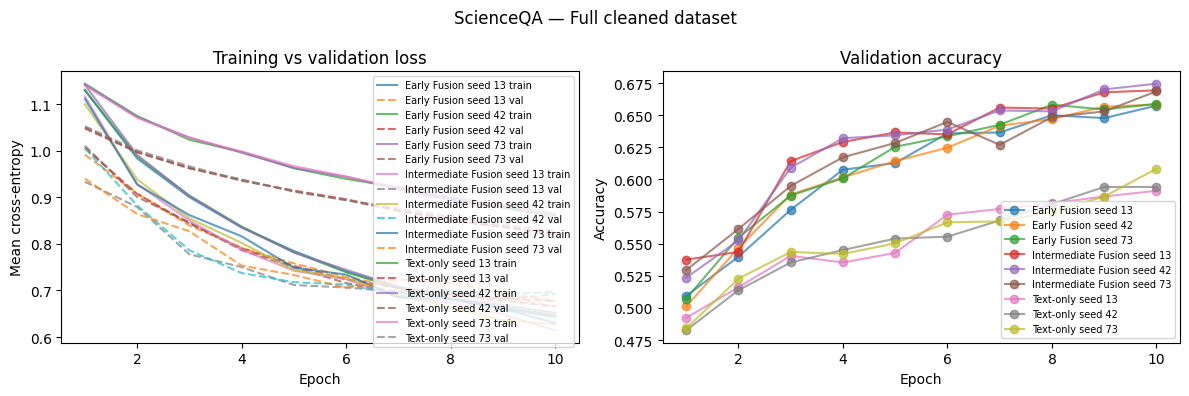

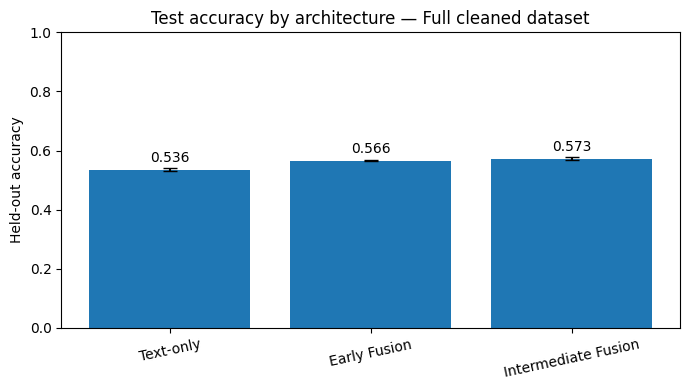

              model  seed grouping            value    n  accuracy
       Early Fusion    13  subject language science   44  0.386364
       Early Fusion    13  subject  natural science 1209  0.526882
       Early Fusion    13  subject   social science  764  0.645288
       Early Fusion    42  subject language science   44  0.386364
       Early Fusion    42  subject  natural science 1209  0.515302
       Early Fusion    42  subject   social science  764  0.647906
       Early Fusion    73  subject language science   44  0.409091
       Early Fusion    73  subject  natural science 1209  0.516956
       Early Fusion    73  subject   social science  764  0.654450
Intermediate Fusion    13  subject language science   44  0.454545
Intermediate Fusion    13  subject  natural science 1209  0.524400
Intermediate Fusion    13  subject   social science  764  0.653141
Intermediate Fusion    42  subject language science   44  0.431818
Intermediate Fusion    42  subject  natural science 1209  0.51

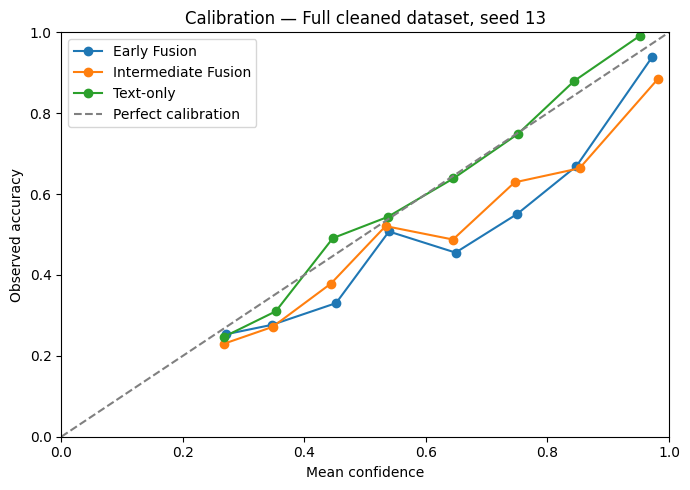

In [ ]:
MODE_LABEL='Pilot subset' if QUICK_RUN else 'Full cleaned dataset'
# Loss curves
fig,axes=plt.subplots(1,2,figsize=(12,4))
for (name,seed),g in history_df.groupby(['model','seed']):
    g=g.sort_values('epoch')
    axes[0].plot(g.epoch,g.train_loss,alpha=.7,label=f'{name} seed {seed} train')
    axes[0].plot(g.epoch,g.val_loss,alpha=.7,linestyle='--',label=f'{name} seed {seed} val')
    axes[1].plot(g.epoch,g.val_accuracy,marker='o',alpha=.7,label=f'{name} seed {seed}')
axes[0].set(title='Training vs validation loss',xlabel='Epoch',ylabel='Mean cross-entropy')
axes[1].set(title='Validation accuracy',xlabel='Epoch',ylabel='Accuracy')
axes[0].legend(fontsize=7);axes[1].legend(fontsize=7)
fig.suptitle(f'ScienceQA — {MODE_LABEL}')
fig.tight_layout();fig.savefig(RESULTS/'learning_curves.png',dpi=180,bbox_inches='tight');plt.show()
# Model comparison across seeds
sub=metrics_df[metrics_df.split=='test']
fig,ax=plt.subplots(figsize=(7,4))
names=list(BUILDERS)
means=[sub[sub.model==m].accuracy.mean() for m in names]
stds=[sub[sub.model==m].accuracy.std(ddof=1) if len(SEEDS)>1 else 0.0 for m in names]
ax.bar(names,means,yerr=stds,capsize=5)
ax.set(ylabel='Held-out accuracy',ylim=(0,1),title=f'Test accuracy by architecture — {MODE_LABEL}')
ax.tick_params(axis='x',labelrotation=12)
for i,v in enumerate(means):ax.text(i,min(.98,v+.025),f'{v:.3f}',ha='center')
fig.tight_layout();fig.savefig(RESULTS/'model_comparison.png',dpi=180,bbox_inches='tight');plt.show()
# Subject / answer count breakdowns
subgroup=[]
for (name,seed),g in pred_df.groupby(['model','seed']):
    for col in ['subject','grade','n_choices']:
        for val,h in g.groupby(col):
            subgroup.append({'model':name,'seed':seed,'grouping':col,
                             'value':val,'n':len(h),'accuracy':h.correct.mean()})
pd.DataFrame(subgroup).to_csv(RESULTS/'subgroup_accuracy.csv',index=False)
print(pd.DataFrame(subgroup).query('grouping=="subject"').head(15).to_string(index=False))
# Reliability diagram: pooled over selected seed only, no fictitious combined independent samples
fig,ax=plt.subplots(figsize=(7,5))
for name,g in pred_df[pred_df.seed==SEEDS[0]].groupby('model'):
    edges=np.linspace(0,1,11);points=[]
    for low,high in zip(edges[:-1],edges[1:]):
        z=g[(g.confidence>=low)&(g.confidence<(high if high<1 else 1.00001))]
        if len(z):points.append((z.confidence.mean(),z.correct.mean()))
    if points:ax.plot(*zip(*points),marker='o',label=name)
ax.plot([0,1],[0,1],linestyle='--',color='gray',label='Perfect calibration')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean confidence',ylabel='Observed accuracy',
       title=f'Calibration — {MODE_LABEL}, seed {SEEDS[0]}')
ax.legend();fig.tight_layout();fig.savefig(RESULTS/'reliability.png',dpi=180,bbox_inches='tight');plt.show()

## 10 — Does the model use the image? Shuffling diagnostic

A cross-modal model may achieve high scores by relying on textual shortcuts. Shuffling held-out image embeddings breaks the image–question correspondence while preserving the marginal image-feature distribution. A meaningful accuracy drop supports image sensitivity, but the test is **not** proof that the model reasons about the diagram. The text-only baseline should be unaffected.

In [ ]:
shuffle_rows=[]
test=features['test']; rand=np.random.default_rng(2026)
perm=torch.as_tensor(rand.permutation(len(test['labels'])),dtype=torch.long)
shuffled=test['patches'][perm]
shuffled_mask=test['patch_mask'][perm]
for seed in SEEDS:
    for name in BUILDERS:
        model=trained_models[(name,seed)].to(DEVICE)
        orig,_=probabilities(model,'test')
        altered,_=probabilities(model,'test',patch_override=shuffled,patch_mask_override=shuffled_mask)
        y=test['labels'].numpy()
        shuffle_rows.append({'model':name,'seed':seed,
                             'accuracy_original':metric_dict(orig,y)['accuracy'],
                             'accuracy_shuffled_images':metric_dict(altered,y)['accuracy'],
                             'difference_original_minus_shuffled':metric_dict(orig,y)['accuracy']-metric_dict(altered,y)['accuracy']})
        model.cpu()
shuffle_df=pd.DataFrame(shuffle_rows)
shuffle_df.to_csv(RESULTS/'image_shuffle_diagnostic.csv',index=False)
print(shuffle_df.to_string(index=False))

              model  seed  accuracy_original  accuracy_shuffled_images  difference_original_minus_shuffled
          Text-only    13           0.530987                  0.530987                            0.000000
       Early Fusion    13           0.568666                  0.567675                            0.000992
Intermediate Fusion    13           0.571641                  0.534953                            0.036688
          Text-only    42           0.541894                  0.541894                            0.000000
       Early Fusion    42           0.562717                  0.561725                            0.000992
Intermediate Fusion    42           0.567179                  0.519584                            0.047595
          Text-only    73           0.534457                  0.534457                            0.000000
       Early Fusion    73           0.566683                  0.563708                            0.002975
Intermediate Fusion    73           0

## 11 — Paired image-group bootstrap accuracy differences

Resample image groups **with replacement** rather than treating repeated questions about one diagram as independent. Each bootstrap compares two models on the *same test rows and seed*. A positive interval for a model minus text baseline supports better accuracy on this held-out set, but the inferential limitation of using one benchmark remains. At 3 seeds, report variability separately.

def paired_image_group_bootstrap(model_a, model_b, seed, reps=500, random_state=1001):
    A=pred_df[(pred_df.model==model_a)&(pred_df.seed==seed)].sort_values('row_index')
    B=pred_df[(pred_df.model==model_b)&(pred_df.seed==seed)].sort_values('row_index')
    assert A.row_index.tolist()==B.row_index.tolist()
    image_groups=A.image_hash.to_numpy()
    names=np.unique(image_groups)
    groups={x:np.flatnonzero(image_groups==x) for x in names}
    ra=A.correct.to_numpy(dtype=float);rb=B.correct.to_numpy(dtype=float)
    rng=np.random.default_rng(random_state)
    draws=[]
    for _ in range(reps):
        sampled=rng.choice(names,size=len(names),replace=True)
        ix=np.concatenate([groups[x] for x in sampled])
        draws.append(float((ra[ix]-rb[ix]).mean()))
    return {'model':model_a,'versus':model_b,'seed':seed,'observed_difference':float((ra-rb).mean()),
            'ci_lower_95':float(np.percentile(draws,2.5)),
            'ci_upper_95':float(np.percentile(draws,97.5)),
            'bootstrap_replicates':reps,'image_groups':len(names)}

boot=[]
for seed in SEEDS:
    for n in ('Early Fusion','Intermediate Fusion'):
        boot.append(paired_image_group_bootstrap(n,'Text-only',seed))
boot_df=pd.DataFrame(boot)
boot_df.to_csv(RESULTS/'paired_group_bootstrap.csv',index=False)
print(boot_df.to_string(index=False))

## 12 — Error review and reproducibility outputs

Manual error examples can reveal whether image text, spatial relationships, ambiguous options or subject-specific concepts are challenging. Automatically exported examples are **candidates for human inspection**, not validated error causes. This cell exports code/configuration metadata and a ZIP of **small** artefacts

In [ ]:
errors=[]
first_seed=SEEDS[0]
for name in BUILDERS:
    wrong=pred_df[(pred_df.model==name)&(pred_df.seed==first_seed)&(pred_df.correct==0)]
    for _,z in wrong.sort_values('confidence',ascending=False).head(15).iterrows():
        ex=raw['test'][int(z['row_index'])]
        errors.append({'model':name,'seed':first_seed,'confidence':float(z['confidence']),
                       'subject':z['subject'],'grade':z['grade'],
                       'question':ex['question'],'choices':json.dumps(ex['choices'],ensure_ascii=False),
                       'correct_option_index':int(z['y_true']),'predicted_option_index':int(z['y_pred']),
                       'error_cause_manual_review':'NOT YET REVIEWED'})
pd.DataFrame(errors).to_csv(RESULTS/'high_confidence_errors_for_review.csv',index=False)
import importlib.metadata as im
packages=['torch','transformers','datasets','numpy','pandas','scikit-learn','Pillow','matplotlib']
versions={p:im.version(p) for p in packages}
versions.update({'python':platform.python_version(),'device':str(DEVICE),'pytorch_cuda':str(torch.version.cuda)})
(RESULTS/'environment_versions.json').write_text(json.dumps(versions,indent=2))
manifest['completed_utc']=datetime.now(timezone.utc).isoformat()
manifest['package_versions']=versions
(RESULTS/'experiment_manifest.json').write_text(json.dumps(manifest,indent=2))
readme="""# ScienceQA-IMG experimental results

These files are *measured outputs* produced by the notebook, not manually entered values.

- model_metrics.csv: accuracy, cross entropy, Brier, ECE, timing and memory by model and seed
- learning_history.csv and learning_curves.png: train/validation learning curves
- test_predictions.csv: paired held-out predictions by question
- paired_group_bootstrap.csv: paired differences resampling image groups
- image_shuffle_diagnostic.csv: impact of breaking image-question correspondence
- subgroup_accuracy.csv: accuracy by subject, grade, and number of options
- high_confidence_errors_for_review.csv: errors requiring manual interpretation
- experiment_manifest.json, environment_versions.json: reproducibility and audit metadata

Check quick_run in the manifest. QUICK RUN results are pilot subset results, not full cleaned-dataset results.
Large model checkpoints and embedding caches are separate from this ZIP.
"""
(RESULTS/'README.md').write_text(readme)
import shutil
out_zip=shutil.make_archive(str(ROOT/'scienceqa_results'),'zip',root_dir=RESULTS)
print('RESULTS ZIP:',out_zip)
if Path('/content').exists():
    from google.colab import files
    files.download(out_zip)

RESULTS ZIP: /content/scienceqa_project22/scienceqa_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>